# Hourly mean temperature (mean diurnal cycle)

For each sensor: the mean temperature for every hour of the day (0 to 23 h CEST), averaged over all days from 15 Sep to 12 Oct 2026. Hour 13 holds the values from 13:00 to 14:00.

- profile mast: Vaisala HMP110 at 8, 4, 2, 1 and 0.5 m (`profile.csv`)
- iWS station: T sensor, RH/T sensor and CNR4 radiometer body (`iws.csv`)
- CNR1 radiometer body (`cnr1.csv`)
- turbulence mast: sonic temperature and thermocouples Tc1 and Tc2 (`turb.csv`)

Data loading and cleaning are the same as in `MAIO_Temp_DailyMean.ipynb`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
ds_profile = pd.read_csv("../data/profile.csv")
ds_iWS = pd.read_csv("../data/iws.csv")
ds_CNR1 = pd.read_csv("../data/cnr1.csv")
ds_turb = pd.read_csv("../data/turb.csv")

In [3]:
#creating timestamps in CEST at the start of each 30-min interval
ds_profile["datetime"] = pd.to_datetime("2026-01-01")+pd.to_timedelta(ds_profile["DOY"]-1,unit="D").dt.round("min")-pd.Timedelta("30min")
ds_CNR1["datetime"] = pd.to_datetime("2026-01-01")+pd.to_timedelta(ds_CNR1["doy"]-1,unit="D").dt.round("min")-pd.Timedelta("30min")
ds_turb["datetime"] = pd.to_datetime("2026-01-01")+pd.to_timedelta(ds_turb["DOY"]-1,unit="D").dt.round("min")-pd.Timedelta("30min")

ds_iWS["datetime"] = (pd.to_datetime(ds_iWS[["year", "mm", "dd"]].rename(columns={"mm": "month", "dd": "day"}))
    + pd.to_timedelta(ds_iWS["hh"], unit="h")
    + pd.to_timedelta(ds_iWS["minutes"], unit="m")
    + pd.to_timedelta(2, unit="h")                     #iWS logs in UTC, the other loggers in CEST (UTC+2)
    - pd.Timedelta("30min"))

ds_profile = ds_profile.set_index("datetime")
ds_iWS = ds_iWS.set_index("datetime")
ds_CNR1 = ds_CNR1.set_index("datetime")
ds_turb = ds_turb.set_index("datetime")

In [4]:
#removing bad values (see README, Problems found in the data)
ds_profile = ds_profile.loc[ds_profile["T1"] > -10]                    #first profile record is invalid (about -25 C)
ds_CNR1 = ds_CNR1.loc[ds_CNR1["SWTop_Avg"].between(-20, 1400)]         #first record and the logger repair on 28 Sep
ds_iWS = ds_iWS.replace(327.67, float("nan"))                          #327.67 is the iWS fill value
ds_turb.loc[(ds_turb["Tc1"] - ds_turb["Ts"]).abs() > 3, "Tc1"] = float("nan")   #thermocouple spikes

In [5]:
temp_vaisala_8m = ds_profile["T1"]
temp_vaisala_4m = ds_profile["T2"]
temp_vaisala_2m = ds_profile["T3"]
temp_vaisala_1m = ds_profile["T4"]
temp_vaisala_05m = ds_profile["T5"]

temp_iws_t = ds_iWS["THUTavg"]         #iWS temperature sensor
temp_iws_rht = ds_iWS["RHTavg"]        #temperature of the iWS humidity sensor
temp_cnr4 = ds_iWS["NRTavg"]           #CNR4 radiometer body

temp_cnr1 = ds_CNR1["cnr1_T_C_Avg"]    #CNR1 radiometer body

temp_sonic = ds_turb["Ts"]             #temperature deduced from sonic anemometer data
temp_tc1 = ds_turb["Tc1"]              #thermocouple close to the sonic anemometer
temp_tc2 = ds_turb["Tc2"]              #thermocouple close to the vertical propeller

## Hourly mean

`groupby(index.hour)` puts all values of the same hour of the day together and averages them.

Two sensors cover fewer days, so their diurnal cycle comes from a different set of days:
- CNR1 body: only from the logger repair on 28 Sep 14:00 onward, because the body temperature was biased before.
- Thermocouple Tc1: mostly missing after 28 Sep, so its cycle comes mainly from 15 to 28 Sep.

The differences from the Vaisala (last figure) are computed per 30-min value first and then averaged per hour, so each sensor is only compared with the Vaisala at the same times.

In [6]:
temp_cnr1 = temp_cnr1.loc["2026-09-28 14:00":]      #CNR1 body temperature is biased before the logger repair

hourly_vaisala_8m = temp_vaisala_8m.groupby(temp_vaisala_8m.index.hour).mean()
hourly_vaisala_4m = temp_vaisala_4m.groupby(temp_vaisala_4m.index.hour).mean()
hourly_vaisala_2m = temp_vaisala_2m.groupby(temp_vaisala_2m.index.hour).mean()
hourly_vaisala_1m = temp_vaisala_1m.groupby(temp_vaisala_1m.index.hour).mean()
hourly_vaisala_05m = temp_vaisala_05m.groupby(temp_vaisala_05m.index.hour).mean()

hourly_iws_t = temp_iws_t.groupby(temp_iws_t.index.hour).mean()
hourly_iws_rht = temp_iws_rht.groupby(temp_iws_rht.index.hour).mean()
hourly_cnr4 = temp_cnr4.groupby(temp_cnr4.index.hour).mean()

hourly_cnr1 = temp_cnr1.groupby(temp_cnr1.index.hour).mean()

hourly_sonic = temp_sonic.groupby(temp_sonic.index.hour).mean()
hourly_tc1 = temp_tc1.groupby(temp_tc1.index.hour).mean()
hourly_tc2 = temp_tc2.groupby(temp_tc2.index.hour).mean()

hourly_vaisala_4m.round(2)

datetime
0     13.92
1     13.62
2     13.46
3     13.21
4     13.03
5     12.95
6     12.74
7     12.73
8     13.06
9     14.17
10    15.51
11    16.58
12    17.56
13    18.19
14    18.75
15    19.10
16    19.04
17    18.74
18    18.06
19    16.82
20    15.88
21    15.18
22    14.65
23    14.23
Name: T2, dtype: float64

## Hourly mean per dataset

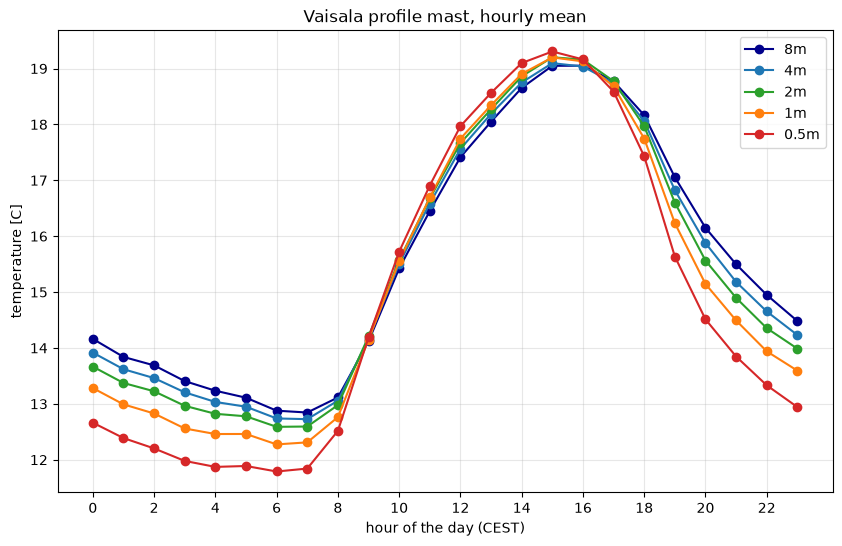

In [7]:
plt.figure(figsize=[10,6])
plt.plot(hourly_vaisala_8m.index,hourly_vaisala_8m,c="darkblue",marker="o",label="8m")
plt.plot(hourly_vaisala_4m.index,hourly_vaisala_4m,c="tab:blue",marker="o",label="4m")
plt.plot(hourly_vaisala_2m.index,hourly_vaisala_2m,c="tab:green",marker="o",label="2m")
plt.plot(hourly_vaisala_1m.index,hourly_vaisala_1m,c="tab:orange",marker="o",label="1m")
plt.plot(hourly_vaisala_05m.index,hourly_vaisala_05m,c="tab:red",marker="o",label="0.5m")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(range(0,24,2))
plt.xlabel("hour of the day (CEST)")
plt.ylabel("temperature [C]")
plt.title("Vaisala profile mast, hourly mean")
plt.show()

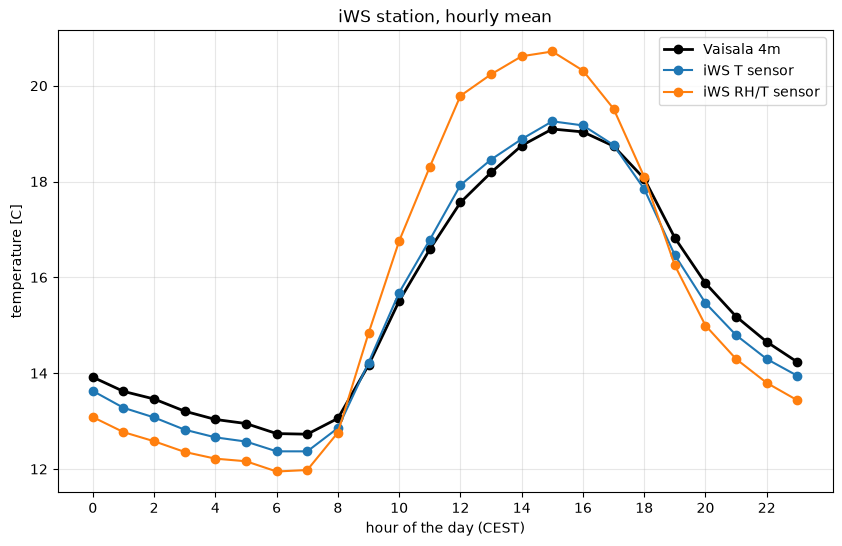

In [8]:
plt.figure(figsize=[10,6])
plt.plot(hourly_vaisala_4m.index,hourly_vaisala_4m,c="black",marker="o",lw=2,label="Vaisala 4m")
plt.plot(hourly_iws_t.index,hourly_iws_t,c="tab:blue",marker="o",label="iWS T sensor")
plt.plot(hourly_iws_rht.index,hourly_iws_rht,c="tab:orange",marker="o",label="iWS RH/T sensor")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(range(0,24,2))
plt.xlabel("hour of the day (CEST)")
plt.ylabel("temperature [C]")
plt.title("iWS station, hourly mean")
plt.show()

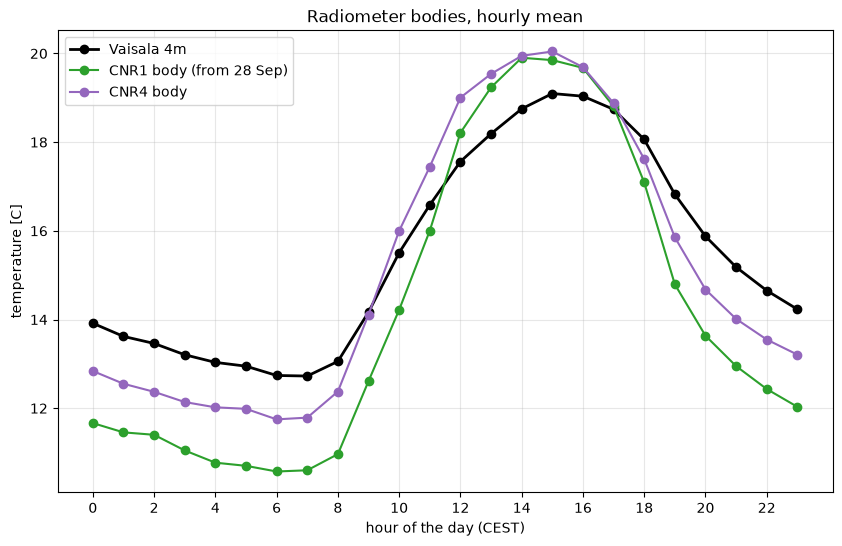

In [9]:
plt.figure(figsize=[10,6])
plt.plot(hourly_vaisala_4m.index,hourly_vaisala_4m,c="black",marker="o",lw=2,label="Vaisala 4m")
plt.plot(hourly_cnr1.index,hourly_cnr1,c="tab:green",marker="o",label="CNR1 body (from 28 Sep)")
plt.plot(hourly_cnr4.index,hourly_cnr4,c="tab:purple",marker="o",label="CNR4 body")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(range(0,24,2))
plt.xlabel("hour of the day (CEST)")
plt.ylabel("temperature [C]")
plt.title("Radiometer bodies, hourly mean")
plt.show()

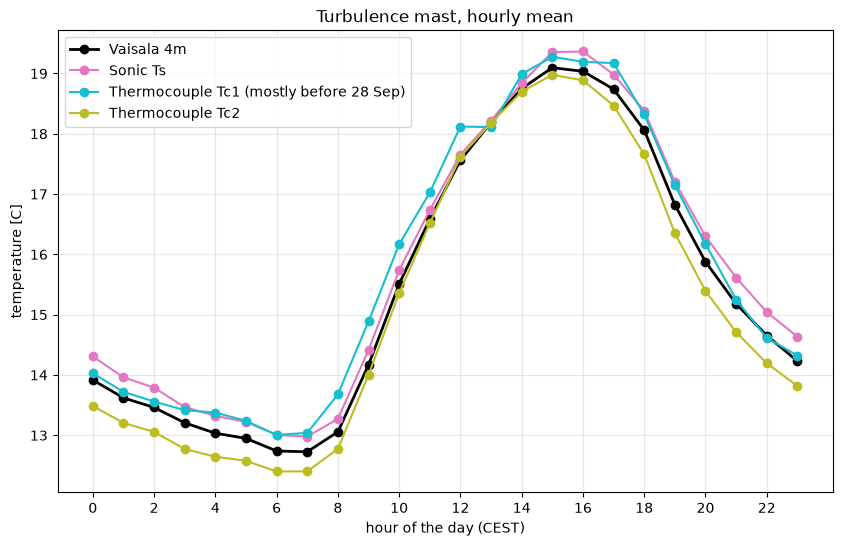

In [10]:
plt.figure(figsize=[10,6])
plt.plot(hourly_vaisala_4m.index,hourly_vaisala_4m,c="black",marker="o",lw=2,label="Vaisala 4m")
plt.plot(hourly_sonic.index,hourly_sonic,c="tab:pink",marker="o",label="Sonic Ts")
plt.plot(hourly_tc1.index,hourly_tc1,c="tab:cyan",marker="o",label="Thermocouple Tc1 (mostly before 28 Sep)")
plt.plot(hourly_tc2.index,hourly_tc2,c="tab:olive",marker="o",label="Thermocouple Tc2")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(range(0,24,2))
plt.xlabel("hour of the day (CEST)")
plt.ylabel("temperature [C]")
plt.title("Turbulence mast, hourly mean")
plt.show()

## Hourly mean difference from the Vaisala at 4 m

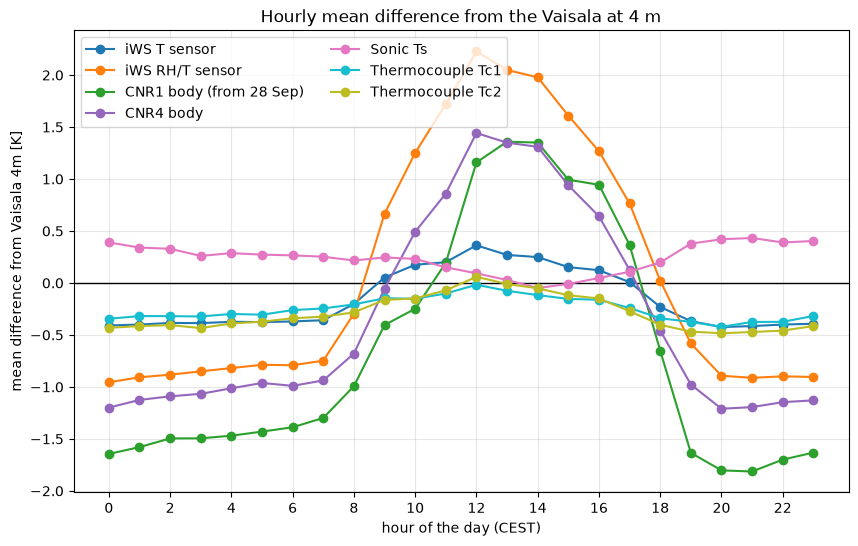

In [11]:
#difference per 30-min value first, then the mean per hour of the day
diff_iws_t = temp_iws_t - temp_vaisala_4m
diff_iws_rht = temp_iws_rht - temp_vaisala_4m
diff_cnr1 = temp_cnr1 - temp_vaisala_4m
diff_cnr4 = temp_cnr4 - temp_vaisala_4m
diff_sonic = temp_sonic - temp_vaisala_4m
diff_tc1 = temp_tc1 - temp_vaisala_4m
diff_tc2 = temp_tc2 - temp_vaisala_4m

hourly_diff_iws_t = diff_iws_t.groupby(diff_iws_t.index.hour).mean()
hourly_diff_iws_rht = diff_iws_rht.groupby(diff_iws_rht.index.hour).mean()
hourly_diff_cnr1 = diff_cnr1.groupby(diff_cnr1.index.hour).mean()
hourly_diff_cnr4 = diff_cnr4.groupby(diff_cnr4.index.hour).mean()
hourly_diff_sonic = diff_sonic.groupby(diff_sonic.index.hour).mean()
hourly_diff_tc1 = diff_tc1.groupby(diff_tc1.index.hour).mean()
hourly_diff_tc2 = diff_tc2.groupby(diff_tc2.index.hour).mean()

plt.figure(figsize=[10,6])
plt.axhline(0,c="black",lw=1)
plt.plot(hourly_diff_iws_t.index,hourly_diff_iws_t,c="tab:blue",marker="o",label="iWS T sensor")
plt.plot(hourly_diff_iws_rht.index,hourly_diff_iws_rht,c="tab:orange",marker="o",label="iWS RH/T sensor")
plt.plot(hourly_diff_cnr1.index,hourly_diff_cnr1,c="tab:green",marker="o",label="CNR1 body (from 28 Sep)")
plt.plot(hourly_diff_cnr4.index,hourly_diff_cnr4,c="tab:purple",marker="o",label="CNR4 body")
plt.plot(hourly_diff_sonic.index,hourly_diff_sonic,c="tab:pink",marker="o",label="Sonic Ts")
plt.plot(hourly_diff_tc1.index,hourly_diff_tc1,c="tab:cyan",marker="o",label="Thermocouple Tc1")
plt.plot(hourly_diff_tc2.index,hourly_diff_tc2,c="tab:olive",marker="o",label="Thermocouple Tc2")
plt.legend(ncol=2)
plt.grid(alpha=0.3)
plt.xticks(range(0,24,2))
plt.xlabel("hour of the day (CEST)")
plt.ylabel("mean difference from Vaisala 4m [K]")
plt.title("Hourly mean difference from the Vaisala at 4 m")
plt.show()